# League of Legends Rank Predictor – Model 1

This notebook develops the first **baseline Machine Learning model** for predicting a League of Legends player's competitive rank using tabular gameplay statistics.

The target variable is `tier`.

---

## 1. Setup and configuration

This section imports the libraries required for loading the dataset, preparing the data, splitting the dataset, training the baseline model, and evaluating its performance.

The main libraries used are:

- **pandas** – loading and manipulating tabular data.
- **numpy** – numerical operations.
- **pathlib** – handling dataset file paths.
- **scikit-learn** – data splitting, preprocessing, Machine Learning and evaluation.

A fixed `random_state` of **42** is used so that the same results can be reproduced.

In [19]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

RANDOM_STATE = 42

# 2. Load the dataset

The dataset is stored in ten separate CSV files, with one file for each League of Legends rank:

- IRON
- BRONZE
- SILVER
- GOLD
- PLATINUM
- EMERALD
- DIAMOND
- MASTER
- GRANDMASTER
- CHALLENGER

Each file contains player-level match statistics.

The files are loaded and combined into one DataFrame. The rank name from each file is added as the target variable `tier`.

During Data Understanding, a small number of rows were found to have a missing `role`. These rows are removed before the model is trained.

In [20]:
folder = Path("../data/raw")

ranks = [
    "iron",
    "bronze",
    "silver",
    "gold",
    "platinum",
    "emerald",
    "diamond",
    "master",
    "grandmaster",
    "challenger"
]

dfs = []

for rank in ranks:
    temp = pd.read_csv(folder / f"{rank}.csv")
    temp["tier"] = rank.upper()
    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

# Remove rows with missing roles
df = df.dropna(subset=["role"]).copy()

print("Dataset shape:", df.shape)
print("Unique players:", df["puuid"].nunique())

print("\nRank distribution:")
print(df["tier"].value_counts())

Dataset shape: (204734, 26)
Unique players: 4340

Rank distribution:
tier
DIAMOND        24782
MASTER         24679
PLATINUM       23858
GOLD           22883
SILVER         22843
BRONZE         20217
GRANDMASTER    19791
IRON           18551
EMERALD        17186
CHALLENGER      9944
Name: count, dtype: int64


# 3. Train, validation and test split

The dataset is split into three parts:

- **70% training data** – used to train the model.
- **20% validation data** – used to evaluate Model 1 and compare future improvements.
- **10% test data** – kept separate until the final model has been selected.

The split is performed by unique player using `puuid`, rather than by individual match rows.

This is important because each player appears in multiple matches. If match rows were split randomly, the same player could appear in both the training and validation or test sets. This could cause data leakage and make the model performance appear better than it actually is.

The split is stratified by `tier` so that the rank distribution remains similar across the training, validation and test sets.

In [21]:
# One row per unique player
player_ranks = df[["puuid", "tier"]].drop_duplicates()

# 70% train, 30% remaining
train_players, temp_players = train_test_split(
    player_ranks,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=player_ranks["tier"]
)

# Split remaining 30% into 20% validation and 10% test
val_players, test_players = train_test_split(
    temp_players,
    test_size=1/3,
    random_state=RANDOM_STATE,
    stratify=temp_players["tier"]
)

print("Train players:", len(train_players))
print("Validation players:", len(val_players))
print("Test players:", len(test_players))

Train players: 3038
Validation players: 868
Test players: 434


In [22]:
# Get all match rows belonging to each group of players
train_df = df[df["puuid"].isin(train_players["puuid"])].copy()
val_df = df[df["puuid"].isin(val_players["puuid"])].copy()
test_df = df[df["puuid"].isin(test_players["puuid"])].copy()

print("Train rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Test rows:", len(test_df))

Train rows: 143391
Validation rows: 40905
Test rows: 20438


In [23]:
print(
    "Train / Validation overlap:",
    len(set(train_df["puuid"]) & set(val_df["puuid"]))
)

print(
    "Train / Test overlap:",
    len(set(train_df["puuid"]) & set(test_df["puuid"]))
)

print(
    "Validation / Test overlap:",
    len(set(val_df["puuid"]) & set(test_df["puuid"]))
)

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


# 4. Feature selection

For Model 1, only numerical gameplay statistics are used as input features.

The target variable is `tier`, which represents the player's competitive rank.

The following columns are excluded from the model:

- `match_id` – identifies the match.
- `puuid` – identifies the player.
- `team_id` – identifies the team.
- `game_creation` – represents when the match was created.
- `champ` – categorical feature, which will be tested in a later model.
- `role` – categorical feature, which will be tested in a later model.

Model 1 intentionally uses a simple set of numerical features so that it can act as a baseline. More features can later be added to determine whether they improve rank prediction.

In [24]:
features = [
    "win",
    "kills",
    "deaths",
    "assists",
    "cs",
    "gold",
    "damage",
    "vision",
    "game_duration",
    "dmg_share",
    "gold_share",
    "gold_per_min",
    "damage_per_min",
    "vision_per_min",
    "kill_participation"
]

X_train = train_df[features]
y_train = train_df["tier"]

X_val = val_df[features]
y_val = val_df["tier"]

X_test = test_df[features]
y_test = test_df["tier"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)

print("\nFeatures used:")
print(features)

Training features: (143391, 15)
Validation features: (40905, 15)
Test features: (20438, 15)

Features used:
['win', 'kills', 'deaths', 'assists', 'cs', 'gold', 'damage', 'vision', 'game_duration', 'dmg_share', 'gold_share', 'gold_per_min', 'damage_per_min', 'vision_per_min', 'kill_participation']


In [25]:
print("Missing values in training features:")
print(X_train.isnull().sum())

print("\nData types:")
print(X_train.dtypes)

Missing values in training features:
win                   0
kills                 0
deaths                0
assists               0
cs                    0
gold                  0
damage                0
vision                0
game_duration         0
dmg_share             0
gold_share            0
gold_per_min          0
damage_per_min        0
vision_per_min        0
kill_participation    0
dtype: int64

Data types:
win                     int64
kills                   int64
deaths                  int64
assists                 int64
cs                      int64
gold                    int64
damage                  int64
vision                  int64
game_duration           int64
dmg_share             float64
gold_share            float64
gold_per_min          float64
damage_per_min        float64
vision_per_min        float64
kill_participation    float64
dtype: object


# 5. Baseline model

Model 1 uses a **Decision Tree classifier** as the baseline model.

The Decision Tree is used because it works well with tabular data and can learn non-linear relationships between gameplay statistics.

It is also easy to interpret and provides a simple baseline that can later be compared with a Random Forest model.

The model is trained only on the training set. The validation set will be used afterward to evaluate its performance.

In [26]:
model_1 = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

model_1.fit(X_train, y_train)

print("Model 1 training complete.")

Model 1 training complete.


# 6. Validation evaluation

After training the Decision Tree, the model is evaluated using the **validation set**.

The validation set contains players that were not used during training. This provides a better indication of how well the model can predict the rank of unseen players.

The following metrics are used:

- **Accuracy** – the percentage of predictions that are correct.
- **Macro F1-score** – calculates the F1-score for every rank and gives each rank equal importance.
- **Precision** – how often predictions for a particular rank are correct.
- **Recall** – how many players from each actual rank are correctly identified.
- **F1-score** – balances precision and recall.

The test set is not used at this stage because it is reserved for the final selected model.

In [27]:
# Make predictions on the validation set
val_predictions = model_1.predict(X_val)

# Calculate evaluation metrics
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(
    y_val,
    val_predictions,
    average="macro"
)

print("Model 1 - Decision Tree")
print("-----------------------")
print("Validation Accuracy:", round(val_accuracy, 4))
print("Validation Macro F1:", round(val_macro_f1, 4))

Model 1 - Decision Tree
-----------------------
Validation Accuracy: 0.1788
Validation Macro F1: 0.1786


In [28]:
print("Classification Report:")
print(
    classification_report(
        y_val,
        val_predictions,
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

      BRONZE       0.19      0.19      0.19      4053
  CHALLENGER       0.11      0.11      0.11      1999
     DIAMOND       0.15      0.16      0.16      4947
     EMERALD       0.10      0.11      0.10      3458
        GOLD       0.15      0.15      0.15      4599
 GRANDMASTER       0.15      0.15      0.15      3949
        IRON       0.45      0.44      0.45      3728
      MASTER       0.19      0.18      0.18      4946
    PLATINUM       0.13      0.13      0.13      4675
      SILVER       0.16      0.16      0.16      4551

    accuracy                           0.18     40905
   macro avg       0.18      0.18      0.18     40905
weighted avg       0.18      0.18      0.18     40905



# 7. Overfitting check

A Decision Tree can become very complex and memorize patterns in the training data.

To check whether this happened, the model's performance on the training set is compared with its performance on the validation set.

If the training performance is much higher than the validation performance, this indicates that the model is overfitting and does not generalize well to unseen players.

In [30]:
train_predictions = model_1.predict(X_train)

train_accuracy = accuracy_score(y_train, train_predictions)
train_macro_f1 = f1_score(
    y_train,
    train_predictions,
    average="macro"
)

print("Training Accuracy:", round(train_accuracy, 4))
print("Training Macro F1:", round(train_macro_f1, 4))

print("\nValidation Accuracy:", round(val_accuracy, 4))
print("Validation Macro F1:", round(val_macro_f1, 4))

Training Accuracy: 1.0
Training Macro F1: 1.0

Validation Accuracy: 0.1788
Validation Macro F1: 0.1786


### Model 1 observations

The Decision Tree achieved **100% accuracy and a Macro F1-score of 1.00 on the training set**, but only **17.88% accuracy and a Macro F1-score of 0.1786 on the validation set**.

The large difference between training and validation performance indicates that the Decision Tree is **strongly overfitting**.

The model has learned the training data extremely well but does not generalize effectively to players that were not included during training.

This provides a clear motivation for the next model iteration. A **Random Forest** will be tested because it combines predictions from multiple Decision Trees, which may reduce overfitting and improve generalization.

# 8. Confusion matrix

A confusion matrix is used to visualize which ranks the Decision Tree predicts correctly and which ranks are commonly confused with each other.

The rows represent the actual rank, while the columns represent the predicted rank.

A strong model should have most predictions concentrated along the diagonal of the matrix. Predictions outside the diagonal show where the model is confusing one rank with another.

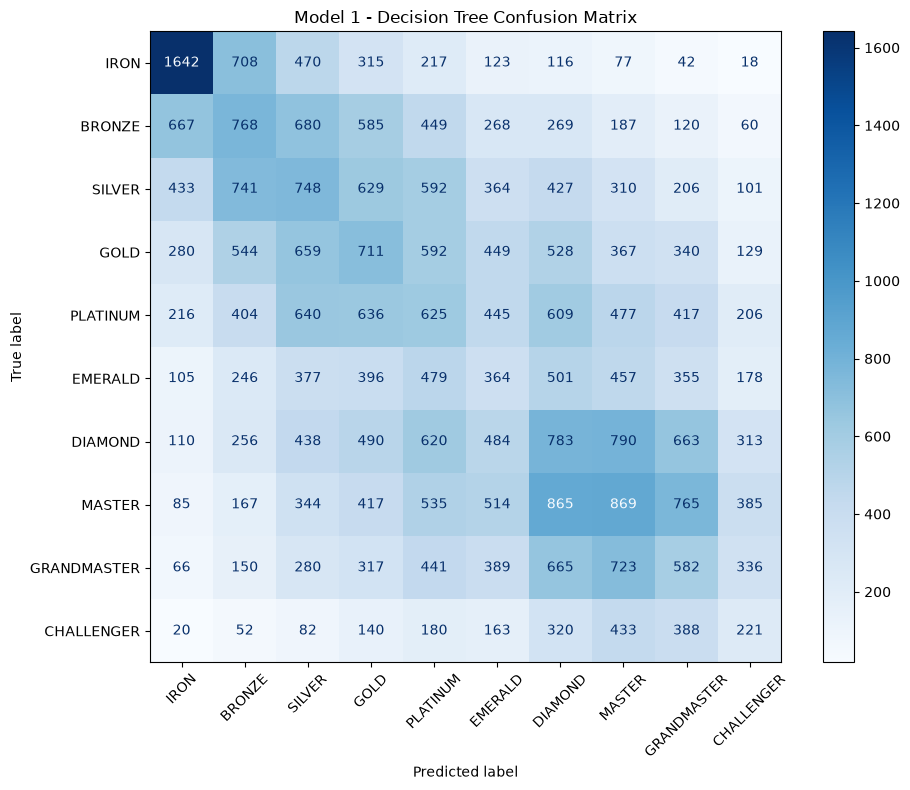

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

rank_order = [
    "IRON",
    "BRONZE",
    "SILVER",
    "GOLD",
    "PLATINUM",
    "EMERALD",
    "DIAMOND",
    "MASTER",
    "GRANDMASTER",
    "CHALLENGER"
]

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    labels=rank_order,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Model 1 - Decision Tree Confusion Matrix")
plt.tight_layout()
plt.show()

### Confusion matrix observations

The confusion matrix shows that Model 1 struggles to clearly separate many of the rank classes.

IRON is predicted more successfully than most other ranks, while ranks such as GOLD, PLATINUM, EMERALD, DIAMOND, MASTER and GRANDMASTER are frequently confused with nearby tiers.

The predictions are spread across many classes instead of being concentrated strongly along the diagonal.

Together with the 100% training accuracy and 17.88% validation accuracy, this confirms that the Decision Tree is strongly overfitting and does not generalize well to unseen players.

Because of this, the next model will use a Random Forest classifier to test whether combining multiple Decision Trees can improve generalization and reduce overfitting.